<a href="https://colab.research.google.com/github/CharuGurusamy/CharuGurusamy/blob/main/Greeting__Card_using_Stable_Diffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
Keyword arguments {'dtype': torch.float16} are not expected by StableDiffusionImg2ImgPipeline and will be ignored.


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

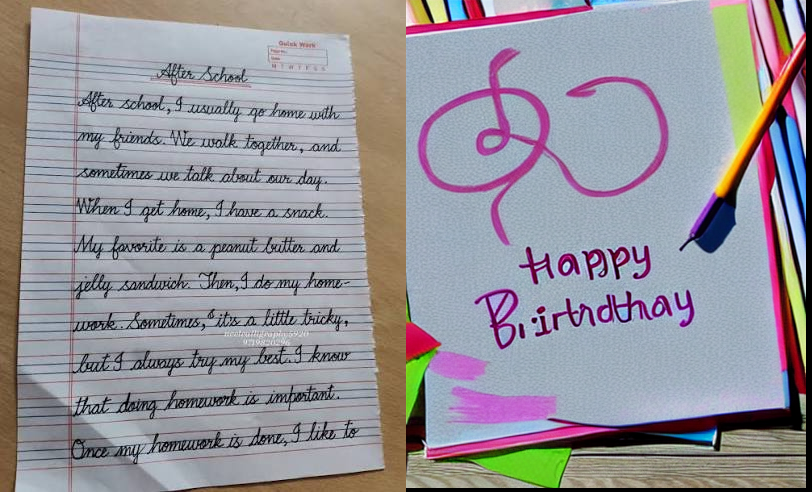

In [1]:
import torch
from diffusers import AutoPipelineForImage2Image
from diffusers.utils import make_image_grid, load_image

pipeline = AutoPipelineForImage2Image.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", dtype=torch.float16, variant="fp16", use_safetensors=True
)
pipeline.enable_model_cpu_offload()
# remove following line if xFormers is not installed or you have PyTorch 2.0 or higher installed
# pipeline.enable_xformers_memory_efficient_attention()

# prepare image
url = "/content/uploaded_greeting_card.jpg" # Updated to use the uploaded image file
init_image = load_image(url)

prompt = "convert this image into a greeting image for birthday , preserve the handwriting with style and color and font size"

# pass prompt and image to pipeline
image = pipeline(prompt, image=init_image).images[0]
make_image_grid([init_image, image], rows=1, cols=2)

The previous error `UnidentifiedImageError` occurred because the URL provided (`https://huggingface.co/buckets/Rathnacharusashticm/GreetingCard/tree/images.jpg`) was not a direct link to an image file. It was likely pointing to an HTML page or a directory listing on Hugging Face.

To fix this, I'll download a direct image file from a public source to the Colab environment and then load that local file.

In [5]:
# Download a sample image for demonstration
!wget -O /content/greeting_card.jpg https://upload.wikimedia.org/wikipedia/commons/e/e9/Christmas_Card_%281900s%29.jpg

--2026-08-23 15:11:25--  https://upload.wikimedia.org/wikipedia/commons/e/e9/Christmas_Card_%281900s%29.jpg
Resolving upload.wikimedia.org (upload.wikimedia.org)... 198.35.26.240, 2620:0:863:ed1a::2:b
Connecting to upload.wikimedia.org (upload.wikimedia.org)|198.35.26.240|:443... connected.
HTTP request sent, awaiting response... 429 Too Many Requests (015d12c)
2026-08-23 15:11:25 ERROR 429: Too Many Requests (015d12c).



Since direct `wget` commands are encountering issues, please upload a greeting card image directly to your Colab environment. Once uploaded, its path will be `/content/uploaded_greeting_card.jpg` (or similar, depending on the filename you use).

In [6]:
from google.colab import files

# This will prompt you to upload a file
uploaded = files.upload()

# Assuming you upload one file, you can get its name
for fn in uploaded.keys():
  print(f'User uploaded file "{fn}"')
  # Rename the uploaded file to a consistent name for the pipeline
  !mv "{fn}" /content/uploaded_greeting_card.jpg
  break # We only expect one image upload

Saving images.jpg to images.jpg
User uploaded file "images.jpg"


Now that we have a local image file, we can modify the previous cell to use this file.